# A VPython turtle on verified periodic routes

I display the saved c=0.5 interface and checked voxel routes. n is the number of voxels per direction. progress counts route steps, and speed is measured in voxels per second of display time. Display time is unrelated to the original simulation time. An enlarged turtle is a marker; its center follows the checked route.

I develop this calculation in small steps. I run a cell, inspect its result and test it before adding the next part. Run the cells in order in Jupyter. A code cell defines a part of the calculation or carries it out; defining a function does not run it.

I permit free noncommercial teaching, learning and demonstrations with acknowledgment. Research and commercial use require my written permission. Earlier licensed releases retain their permissions. [Read the code-use terms](https://saswataiith.github.io/using-my-resources/).

Copyright (c) 2026 Saswata Bhattacharyya.

## A visual story before the code

Can I follow a route without leaving the phase?

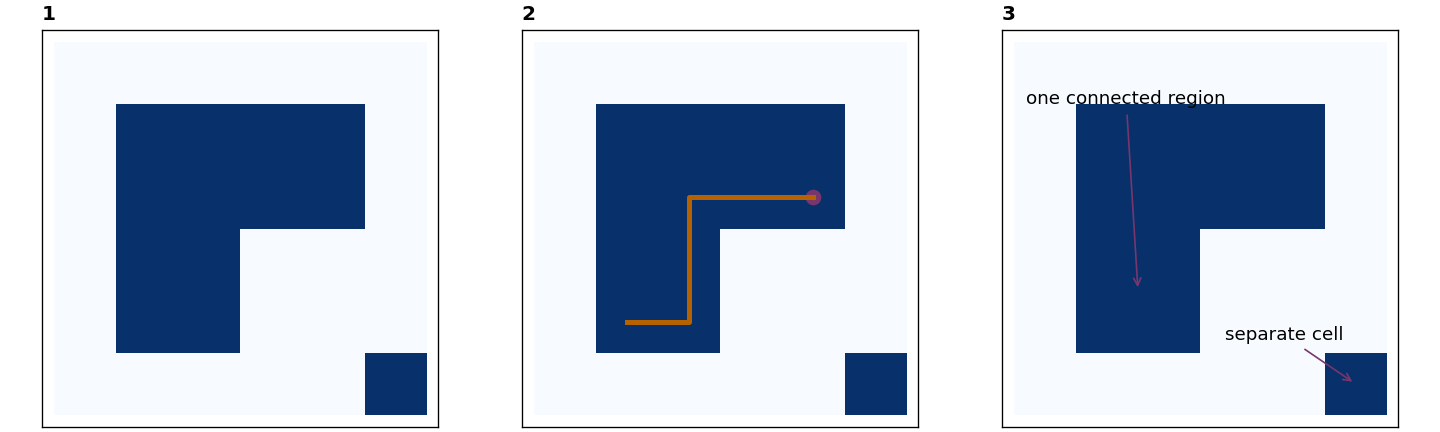

**Panel 1: Choose the allowed region.** Which cells may the turtle enter? A binary mask separates allowed and forbidden cells.

**Panel 2: Follow neighboring occupied cells.** Every step needs a valid connection. The route in the drawing stays inside one edge-connected group. A visual jump would not establish a path.

**Panel 3: Distinguish an address from a journey.** Wrapping the display is not the same as closing a route. For a periodic field, the code keeps wrapped addresses and unwrapped route information. The notebook prepares or validates that data before an optional viewer displays it.

These drawings explain the ideas. They are not numerical output from this notebook. I then follow the code, its recorded results and its checks.


## Step 1: Prepare the Python environment

I install the packages listed in the next cell once in the same environment as the notebook. In Jupyter or Colab, remove the comment marker from the installation line below if a package is missing. NumPy stores arrays and evaluates numerical operations. Matplotlib displays plots. Pillow reads and writes images. This installation does not change the model parameters.

In [1]:
# %pip install numpy vpython "setuptools<82"
import numpy as np
assert np.isfinite(np.array([0.0, 1.0])).all()
print("NumPy is ready:", np.__version__)

NumPy is ready: 2.1.3


## Step 2: Load data and decide when to open the scene

I download the public viewer data, then check the route definitions without opening VPython. I use local Jupyter for the native viewer; Colab does not provide the same interactive VPython environment. I leave the window disabled initially so Run All does not enter an endless display loop.

In [2]:
from pathlib import Path
from urllib.request import urlretrieve

work = Path("lesson-data")
work.mkdir(exist_ok=True)

def get_file(relative_path):
    # I download a public example only when its local copy is missing.
    destination = work / Path(relative_path).name
    if not destination.exists():
        urlretrieve("https://saswataiith.github.io/" + relative_path, destination)
    return destination

viewer_path = get_file("assets/examples/bicontinuity-3d/viewer.json")

viewer_data = __import__("json").loads(viewer_path.read_text())
assert viewer_data["n"] == 256
for phase in ("red", "blue"):
    for axis in "xyz":
        route = np.asarray(viewer_data["routes"][phase][axis])
        steps = (np.diff(route, axis=0) + 128) % 256 - 128
        assert np.all(np.abs(steps).sum(axis=1) == 1)
        assert np.array_equal(steps.sum(axis=0), np.eye(3, dtype=int)["xyz".index(axis)] * 256)
print("All six saved routes have face-sharing steps and the stated winding.")

All six saved routes have face-sharing steps and the stated winding.


## Step 3: The optional interactive viewer

I first run the data checks with this setting left False. To use the viewer in local Jupyter, change it to True, run this cell, then run the cells below it in order. The last cell runs until I interrupt the kernel. I must restart the kernel before rebuilding a second scene.

In [3]:
open_viewer = False

## Step 4: Prepare the next part of the calculation

I define `data`, `n`, `scene`, `scene.forward`, `scene.lights`, `scene.ambient`. These are the same operations as in the original source, written on separate lines so their order is clear. Inspect their values before running the next cell.

In [4]:
if open_viewer:
    import json, sys, time
    from pathlib import Path
    from vpython import canvas, vec, box, compound, ellipsoid, sphere, rate, menu, button, slider, checkbox, wtext, vertex, triangle, distant_light, curve
    data = json.loads(Path(viewer_path).read_text())
    n = data['n']
    scene = canvas(title='Measured 3D bicontinuity: VPython turtle', width=800, height=550, background=vec(0.98, 0.98, 0.96), center=vec(n / 2, n / 2, n / 2), range=n * 0.8)
    scene.forward = vec(-1, -0.7, -1)
    scene.lights = []
    scene.ambient = vec(0.22, 0.22, 0.22)

## Step 5: Prepare the next part of the calculation

I define `colors`, `phases`. These are the same operations as in the original source, written on separate lines so their order is clear. Inspect their values before running the next cell.

In [5]:
if open_viewer:
    distant_light(direction=vec(-0.6, 0.8, -1), color=vec(0.45, 0.45, 0.45))
    distant_light(direction=vec(1, -0.2, 0.4), color=vec(0.18, 0.18, 0.18))
    distant_light(direction=vec(0.3, 0.7, 1), color=vec(0.12, 0.12, 0.12))
    colors = {'red': vec(0.85, 0.14, 0.12), 'blue': vec(0.12, 0.38, 0.85)}
    phases = {}

## Step 6: Repeat the operation and inspect each case

I repeat the operation over the specified cases. Read the loop variable first, then follow what changes on each pass. The assertions check the stated numerical or topological condition.

In [6]:
if open_viewer:
    for name in colors:
        mesh = data['meshes'][name]
        phases[name] = []
        for start in range(0, len(mesh['triangles']), 1500):
            vertices = {}

            def point(i):
                if i not in vertices:
                    vertices[i] = vertex(pos=vec(*mesh['vertices'][i]), normal=vec(*mesh['normals'][i]), color=colors[name])
                return vertices[i]
            faces = [triangle(v0=point(t[0]), v1=point(t[1]), v2=point(t[2])) for t in mesh['triangles'][start:start + 1500]]
            surface = compound(faces)
            surface.opacity = 0.1
            surface.shininess = 0.25
            phases[name].append(surface)

## Step 7: Prepare the next part of the calculation

I define `marker`, `parts`, `offsets`. These are the same operations as in the original source, written on separate lines so their order is clear. Inspect their values before running the next cell.

In [7]:
if open_viewer:
    marker = n / 32
    parts = [ellipsoid(size=vec(0.85 * marker, 0.65 * marker, 1.1 * marker), color=vec(0.2, 0.65, 0.22)), sphere(radius=0.23 * marker, color=vec(0.35, 0.8, 0.3))]
    offsets = [vec(0, 0, 0), vec(0, 0, 0.65)]

## Step 8: Repeat the operation and inspect each case

I repeat the operation over the specified cases. Read the loop variable first, then follow what changes on each pass. The assertions check the stated numerical or topological condition.

In [8]:
if open_viewer:
    for x in (-0.38, 0.38):
        for z in (-0.32, 0.32):
            parts.append(sphere(radius=0.16 * marker, color=vec(0.35, 0.8, 0.3)))
            offsets.append(vec(x, -0.18, z))

## Step 9: Prepare the next part of the calculation

I define `phase`, `direction`, `progress`, `running`, `trails`, `current_trail`, `executed`. These are the same operations as in the original source, written on separate lines so their order is clear. Inspect their values before running the next cell.

In [9]:
if open_viewer:
    phase = 'red'
    direction = 'x'
    progress = 0.0
    running = False
    trails = []
    current_trail = None
    executed = 0.0
    crossings = 0
    route = []

## Step 10: Control interface visibility

I change the displayed opacity and visibility to make the marker easier to see. These controls do not change the field or its connectivity.

In [10]:
if open_viewer:
    def visibility(_=None):
        for name, meshes in phases.items():
            for obj in meshes:
                obj.visible = name == phase and other.checked
                obj.opacity = opacity.value

## Step 11: Interpolate a periodic voxel step

I interpolate only between consecutive verified face-sharing voxels. The shortest periodic displacement identifies a seam step. Display coordinates are wrapped back into the box.

In [11]:
if open_viewer:
    def position_at(q):
        i = min(int(q), len(route) - 2)
        t = 1 if q >= len(route) - 1 else q - i
        a, b = route[i:i + 2]
        d = [(b[j] - a[j] + n // 2) % n - n // 2 for j in range(3)]
        return [(a[j] + 0.5 + d[j] * t) % n for j in range(3)]

## Step 12: A new displayed trail

I create a new curve at the supplied position. A separate curve after a seam crossing avoids drawing a shortcut through the box.

In [12]:
if open_viewer:
    def begin_trail(p):
        global current_trail
        current_trail = curve(pos=[vec(*p)], radius=n / 350, color=vec(0.68, 0.02, 0.42), emissive=True)
        trails.append(current_trail)

## Step 13: The recorded path

I append only the route segments the turtle has executed. At a periodic crossing I end one trail on the face and start another at the opposite face.

In [13]:
if open_viewer:
    def extend_trail(to):
        global executed, crossings
        q = executed
        while q < to - 1e-09:
            i = min(int(q + 1e-09), len(route) - 2)
            end = min(to, i + 1)
            a, b = route[i:i + 2]
            axis = next((j for j in range(3) if abs(b[j] - a[j]) > n / 2), None)
            if axis is not None and q < i + 0.5 - 1e-09 and (end >= i + 0.5):
                face = [x + 0.5 for x in a]
                face[axis] = n if b[axis] < a[axis] else 0
                current_trail.append(pos=vec(*face))
                partner = list(face)
                partner[axis] = 0 if face[axis] == n else n
                begin_trail(partner)
                q = i + 0.5
                crossings += 1
            else:
                current_trail.append(pos=vec(*position_at(end)))
                q = end
        executed = to

## Step 14: Reset the selected route

I reset progress and the executed trail when the phase or winding direction changes. The saved route remains the source of the voxel positions.

In [14]:
if open_viewer:
    def reset(_=None):
        global progress, running, phase, direction, executed, crossings, route
        phase = phase_menu.selected
        direction = direction_menu.selected
        progress = 0.0
        running = False
        executed = 0.0
        crossings = 0
        route = data['routes'][phase][direction]
        for trail in trails:
            trail.clear()
            trail.visible = False
        trails.clear()
        begin_trail(position_at(0))
        visibility()

## Step 15: The animation loop

I change the running state when the user selects Start. The clock loop updates progress while this state is true.

In [15]:
if open_viewer:
    def start(_):
        global running, progress
        if progress >= len(route) - 1:
            reset()
        running = True

## Step 16: Pause the animation

I stop advancing progress while keeping the executed trail visible.

In [16]:
if open_viewer:
    def pause(_):
        global running
        running = False

## Step 17: Prepare the next part of the calculation

I define `phase_menu`, `direction_menu`, `speed`. These are the same operations as in the original source, written on separate lines so their order is clear. Inspect their values before running the next cell.

In [17]:
if open_viewer:
    scene.append_to_caption('\nPhase: ')
    phase_menu = menu(choices=['red', 'blue'], selected='red', bind=reset)
    scene.append_to_caption(' Winding direction: ')
    direction_menu = menu(choices=['x', 'y', 'z'], selected='x', bind=reset)
    button(text='Start', bind=start)
    button(text='Pause', bind=pause)
    button(text='Reset', bind=reset)
    scene.append_to_caption('\nSpeed (voxels/s): ')
    speed = slider(min=5, max=200, value=40, bind=lambda _: None)

## Step 18: Prepare the next part of the calculation

I define `opacity`, `other`, `status`, `last`. These are the same operations as in the original source, written on separate lines so their order is clear. Inspect their values before running the next cell.

In [18]:
if open_viewer:
    scene.append_to_caption('\nc = 0.5 isosurface opacity: ')
    opacity = slider(min=0, max=1, step=0.02, value=0.1, bind=visibility)
    other = checkbox(text='Show c = 0.5 interface', checked=True, bind=visibility)
    scene.append_to_caption('\nRotate: right-drag / Ctrl-drag. Zoom: wheel. Face crossings reappear on the opposite face.\nMagenta records only the executed path. The isosurface has no box-face caps.\nThe enlarged turtle body is a marker; its centre follows checked six-neighbour voxel routes.\n')
    status = wtext(text='')
    reset()
    last = time.perf_counter()

## Step 19: The viewer event loop

I keep the VPython clock running so mouse and button events can update the scene. Run this cell interactively and interrupt the kernel when finished. This is an event loop, not a simulation of phase separation.

In [19]:
if open_viewer:
    while True:
        rate(60)
        now = time.perf_counter()
        dt = min(now - last, 0.1)
        last = now
        route = data['routes'][phase][direction]
        if running:
            progress = min(len(route) - 1, progress + speed.value * dt)
            extend_trail(progress)
            if progress >= len(route) - 1:
                running = False
        p = vec(*position_at(progress))
        for part, offset in zip(parts, offsets):
            part.pos = p + offset * marker
        status.text = f'{phase} · {direction} · step {int(progress)}/{len(route) - 1} · ' + ('complete (winding +1)' if progress >= len(route) - 1 else 'running' if running else 'paused')

## Step 20: Review and extend the calculation

I change one input, predict its effect and compare the result with that prediction. A successful check establishes the tested property; it does not establish convergence or equilibrium. I include the complete calculation in this notebook; no separate script is needed. For a standalone implementation, [email me explaining which code you need, why you need it and how you intend to use it](https://saswataiith.github.io/using-my-resources/#request-code).

<details>
<summary>Run checks</summary>

I first restart the kernel and run all the required cells.

</details>